<a href="https://colab.research.google.com/github/rodrigoviannasn/MAT-422/blob/main/MAT422_HW_3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 — Homework 3.3: Optimization and Gradient Descent

Rodrigo Vianna | 10/18/2026

In [23]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

## 3.3.1 Necessary and Sufficient Conditions of Local Minimizers

Consider the function

$$
f(x)=x^4-4x^2+3.
$$

For a differentiable function, a necessary condition for an interior local minimizer $x^*$ is

$$
f'(x^*)=0.
$$

A sufficient condition for a strict local minimum is

$$
f'(x^*)=0
\quad \text{and} \quad
f''(x^*)>0.
$$

For this function,

$$
f'(x)=4x^3-8x
$$

and

$$
f''(x)=12x^2-8.
$$

The code below checks the critical points and uses the second derivative to classify them.

In [24]:
def f(x):
    return x**4 - 4*x**2 + 3

def f_prime(x):
    return 4*x**3 - 8*x

def f_double_prime(x):
    return 12*x**2 - 8

local_minimizers = np.array([-np.sqrt(2), np.sqrt(2)])
local_maximizer = 0.0

print("Checking the local minimizers:\n")

for point in local_minimizers:
    print(f"x = {point:.4f}")
    print(f"f(x) = {f(point):.4f}")
    print(f"f'(x) = {f_prime(point):.4f}")
    print(f"f''(x) = {f_double_prime(point):.4f}")
    print(
        "Second-derivative test confirms a local minimum:",
        bool(np.isclose(f_prime(point), 0) and f_double_prime(point) > 0)
    )
    print()

print("Checking the critical point x = 0:")
print(f"f'(0) = {f_prime(local_maximizer):.4f}")
print(f"f''(0) = {f_double_prime(local_maximizer):.4f}")
print("Because f''(0) < 0, x = 0 is a local maximum.")

Checking the local minimizers:

x = -1.4142
f(x) = -1.0000
f'(x) = -0.0000
f''(x) = 16.0000
Second-derivative test confirms a local minimum: True

x = 1.4142
f(x) = -1.0000
f'(x) = 0.0000
f''(x) = 16.0000
Second-derivative test confirms a local minimum: True

Checking the critical point x = 0:
f'(0) = 0.0000
f''(0) = -8.0000
Because f''(0) < 0, x = 0 is a local maximum.


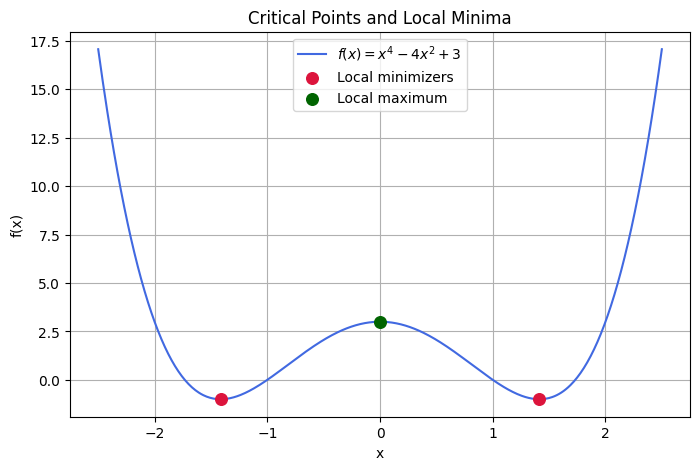

In [25]:
x_values = np.linspace(-2.5, 2.5, 500)

plt.figure(figsize=(8, 5))
plt.plot(x_values, f(x_values), color="royalblue", label=r"$f(x)=x^4-4x^2+3$")

plt.scatter(
    local_minimizers,
    f(local_minimizers),
    color="crimson",
    s=70,
    zorder=3,
    label="Local minimizers"
)

plt.scatter(
    local_maximizer,
    f(local_maximizer),
    color="darkgreen",
    s=70,
    zorder=3,
    label="Local maximum"
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Critical Points and Local Minima")
plt.grid()
plt.legend()
plt.show()

### Section Conclusion

The points $x=-\sqrt{2}$ and $x=\sqrt{2}$ both satisfy the necessary condition because their first derivatives are equal to zero. Their positive second derivatives confirm that they are local minimizers. In contrast, $x=0$ is also a critical point, but its negative second derivative identifies it as a local maximum instead.

## 3.3.2 Convexity and Global Minimizers

Consider the function

$$
g(x)=(x-3)^2+2.
$$

A twice-differentiable function is convex when

$$
g''(x)\geq 0.
$$

For this function,

$$
g''(x)=2>0,
$$

so $g(x)$ is strictly convex. A strictly convex function has only one global minimizer. The minimum occurs where

$$
g'(x)=2(x-3)=0,
$$

which gives $x=3$.

The code also checks the convexity inequality

$$
g(\lambda x_1+(1-\lambda)x_2)
\leq
\lambda g(x_1)+(1-\lambda)g(x_2).
$$

In [26]:
def g(x):
    return (x - 3)**2 + 2

def g_prime(x):
    return 2 * (x - 3)

def g_double_prime(x):
    return 2

global_minimizer = 3.0
minimum_value = g(global_minimizer)

x_1 = 0.0
x_2 = 4.0
lambda_value = 0.25

combined_x = lambda_value * x_1 + (1 - lambda_value) * x_2
left_side = g(combined_x)
right_side = (
    lambda_value * g(x_1)
    + (1 - lambda_value) * g(x_2)
)

print("Second derivative of g(x):", g_double_prime(global_minimizer))
print("Is g(x) strictly convex?", g_double_prime(global_minimizer) > 0)

print("\nGlobal minimizer:", global_minimizer)
print("Minimum value g(3):", minimum_value)
print("Derivative at x = 3:", g_prime(global_minimizer))

print("\nConvexity inequality check:")
print("Left side:", left_side)
print("Right side:", right_side)
print("Does the inequality hold?", bool(left_side <= right_side))

Second derivative of g(x): 2
Is g(x) strictly convex? True

Global minimizer: 3.0
Minimum value g(3): 2.0
Derivative at x = 3: 0.0

Convexity inequality check:
Left side: 2.0
Right side: 5.0
Does the inequality hold? True


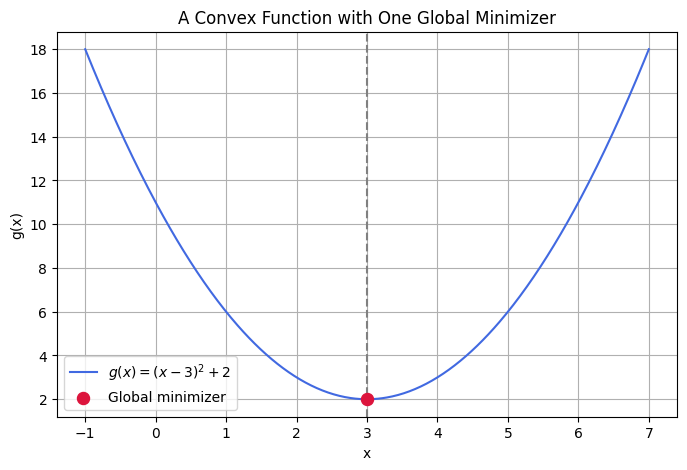

In [27]:
x_values = np.linspace(-1, 7, 500)

plt.figure(figsize=(8, 5))
plt.plot(x_values, g(x_values), color="royalblue", label=r"$g(x)=(x-3)^2+2$")
plt.scatter(
    global_minimizer,
    minimum_value,
    color="crimson",
    s=75,
    zorder=3,
    label="Global minimizer"
)
plt.axvline(global_minimizer, color="gray", linestyle="--")

plt.xlabel("x")
plt.ylabel("g(x)")
plt.title("A Convex Function with One Global Minimizer")
plt.grid()
plt.legend()
plt.show()

### Section Conclusion

Because the second derivative of $g(x)$ is positive everywhere, the graph is convex and opens upward. The critical point at $x=3$ is therefore not only a local minimum but also the unique global minimum. The convexity inequality check also returned True, which supports that the function is convex.

## 3.3.3 Gradient Descent

Gradient descent is an iterative method for finding a minimum of a function. The update rule is

$$
\mathbf{x}_{k+1}
=
\mathbf{x}_k
-
\alpha \nabla F(\mathbf{x}_k),
$$

where $\alpha$ is the learning rate and $\nabla F(\mathbf{x}_k)$ is the gradient.

This example minimizes the two-variable function

$$
F(x,y)=(x-2)^2+2(y+1)^2.
$$

Its gradient is

$$
\nabla F(x,y)
=
\begin{bmatrix}
2(x-2) \\
4(y+1)
\end{bmatrix}.
$$

The function has a global minimum at $(2,-1)$. Starting from a different point, gradient descent should move toward that minimum.

In [28]:
def objective(point):
    x, y = point
    return (x - 2)**2 + 2*(y + 1)**2

def gradient(point):
    x, y = point
    return np.array([
        2 * (x - 2),
        4 * (y + 1)
    ])

learning_rate = 0.15
iterations = 20

current_point = np.array([-4.0, 4.0])
history = [current_point.copy()]
objective_values = [objective(current_point)]

for _ in range(iterations):
    current_point = current_point - learning_rate * gradient(current_point)
    history.append(current_point.copy())
    objective_values.append(objective(current_point))

history = np.array(history)
objective_values = np.array(objective_values)

true_minimum = np.array([2.0, -1.0])

print("Starting point:", history[0])
print("Starting objective value:", objective_values[0])

print("\nSelected gradient descent iterations:")
for step in [0, 1, 2, 5, 10, 20]:
    print(
        f"Step {step:>2}: "
        f"point = {history[step]}, "
        f"F(x, y) = {objective_values[step]:.8f}"
    )

print("\nFinal point:", history[-1])
print("Known minimum:", true_minimum)
print(
    "Distance from the known minimum:",
    np.linalg.norm(history[-1] - true_minimum)
)

Starting point: [-4.  4.]
Starting objective value: 86.0

Selected gradient descent iterations:
Step  0: point = [-4.  4.], F(x, y) = 86.00000000
Step  1: point = [-2.2  1. ], F(x, y) = 25.64000000
Step  2: point = [-0.94 -0.2 ], F(x, y) = 9.92360000
Step  5: point = [ 0.99158 -0.9488 ], F(x, y) = 1.02215378
Step 10: point = [ 1.830515 -0.999476], F(x, y) = 0.02872577
Step 20: point = [ 1.995212 -1.      ], F(x, y) = 0.00002292

Final point: [ 1.995212 -1.      ]
Known minimum: [ 2. -1.]
Distance from the known minimum: 0.004787535978172505


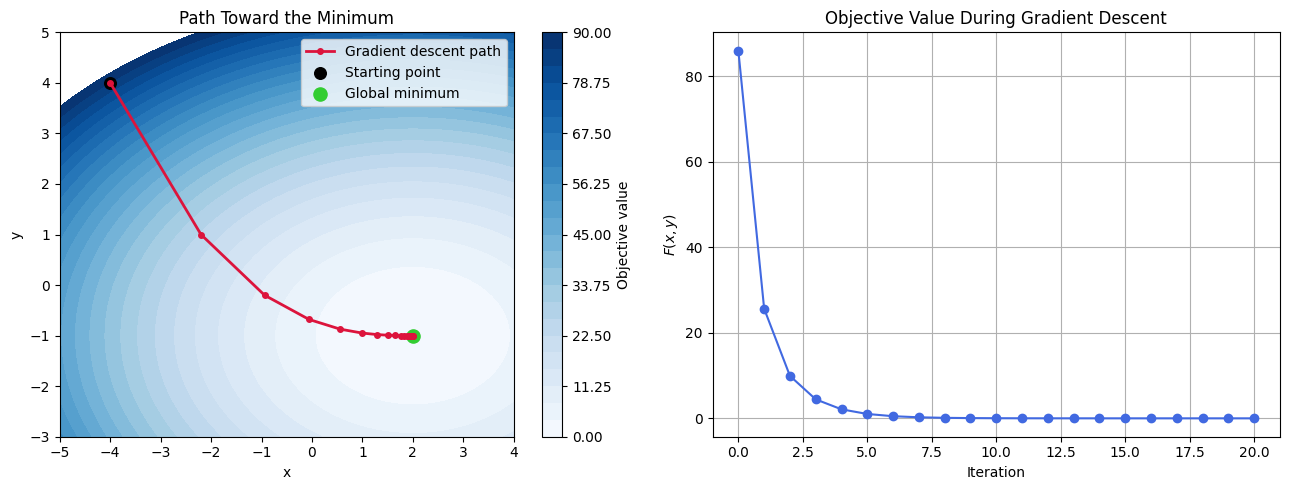

In [29]:

x_grid = np.linspace(-5, 4, 300)
y_grid = np.linspace(-3, 5, 300)
X, Y = np.meshgrid(x_grid, y_grid)
Z = (X - 2)**2 + 2*(Y + 1)**2

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

contours = axes[0].contourf(
    X, Y, Z,
    levels=np.linspace(0, 90, 25),
    cmap="Blues"
)

fig.colorbar(contours, ax=axes[0], label="Objective value")

axes[0].plot(
    history[:, 0],
    history[:, 1],
    color="crimson",
    marker="o",
    linewidth=2,
    markersize=4,
    label="Gradient descent path"
)

axes[0].scatter(
    history[0, 0],
    history[0, 1],
    color="black",
    s=70,
    label="Starting point"
)

axes[0].scatter(
    true_minimum[0],
    true_minimum[1],
    color="limegreen",
    s=90,
    label="Global minimum"
)

axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Path Toward the Minimum")
axes[0].legend()

axes[1].plot(
    np.arange(iterations + 1),
    objective_values,
    color="royalblue",
    marker="o"
)

axes[1].set_xlabel("Iteration")
axes[1].set_ylabel(r"$F(x, y)$")
axes[1].set_title("Objective Value During Gradient Descent")
axes[1].grid()

plt.tight_layout()
plt.show()

### Section Conclusion

The path on the contour plot moved from the starting point toward the global minimum at $(2,-1)$. The graph on the right shows that the objective value decreased during the iterations. This demonstrates that gradient descent moves in the direction opposite to the gradient in order to reduce the function value.

## Conclusion / Reflection

Before working on this homework, I mostly thought of optimization as simply using the derivative of a function to understand its behavior. These examples showed that there are specific mathematical tools for deciding whether a critical point is a minimum and whether that minimum is local or global.

The local-minimizer example made the second derivative test more understandable because it showed that not every point where the first derivative is zero is a minimum. The convexity example was also useful because it showed why a local minimum can be trusted as the global minimum when the function is convex.

Gradient descent was the most practical part for me. Seeing the points move across the contour graph made the update rule easier to understand. The decreasing objective-value graph also made it clear that each iteration was improving the result. Overall, I understand better how derivatives and gradients are used to solve optimization problems.